# Mini-projet Séries Temporelles — Partie 2 : ARIMA / SARIMA / SARIMAX (section 3.1)
Prérequis : avoir exécuté `01_eda.ipynb` (il produit `data/monthly_dataset.csv`). Décisions reprises de l'EDA : cible `log(core)`, d = 1, D = 1, s = 12, indicatrice COVID d'avril 2020, split chronologique 90/10.

**Plan** : (1) identification manuelle à partir de l'ACF/PACF ; (2) recherche automatique (`pmdarima`) et grille explicite par AICc ; (3) diagnostic complet des résidus (Ljung-Box, normalité, ARCH-LM) ; (4) ajout de la température (SARIMAX) ; (5) prévisions h = 10 et h = 24 avec intervalles, métriques MSE/RMSE/MAE/MAPE, comparées à une référence naïve saisonnière.

In [1]:
import warnings, platform, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels, pmdarima as pm
from scipy import stats
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf
from common import load, split, metrics, save_forecasts

warnings.filterwarnings("ignore")
SEED = 42; random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("python", platform.python_version(), "| statsmodels", statsmodels.__version__, "| pmdarima", pm.__version__)

df = load(); df["core_log"] = np.log(df["core"])
train, test = split(df)
ly = train["core_log"]                       # on modélise le LOG (saisonnalité multiplicative, cf. EDA)
X0 = train[["covid_2020_04"]]                # exogène minimale : indicatrice COVID
print(len(train), "mois d'apprentissage |", len(test), "mois de test")

python 3.12.3 | statsmodels 0.15.0 | pmdarima 2.1.1
212 mois d'apprentissage | 24 mois de test


## 1. Identification manuelle (ACF/PACF de l'EDA)
Après Δ Δ₁₂, l'ACF avait des pics négatifs aux retards 1 et 12 → MA(1) régulier + MA(1) saisonnier : **SARIMA(0,1,1)(0,1,1)₁₂** (modèle « airline »).

In [2]:
def fit(order, seas, exog=None, y=ly):
    # enforce_* = False : évite les échecs de convergence liés aux contraintes ; paramètres vérifiés ensuite
    return SARIMAX(y, exog=exog, order=order, seasonal_order=seas, trend="n",
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=300)

m_manual = fit((0, 1, 1), (0, 1, 1, 12), X0)
print(m_manual.summary().tables[1])
print(f"AIC = {m_manual.aic:.1f} | BIC = {m_manual.bic:.1f}")

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
covid_2020_04    -0.2048      0.099     -2.064      0.039      -0.399      -0.010
ma.L1            -0.8284      0.040    -20.706      0.000      -0.907      -0.750
ma.S.L12         -0.7005      0.055    -12.720      0.000      -0.808      -0.593
sigma2            0.0016      0.000     10.441      0.000       0.001       0.002
AIC = -658.2 | BIC = -645.3


**Lecture du modèle manuel.** Les trois coefficients sont significatifs : MA(1) ≈ −0,83 et MA saisonnier ≈ −0,70 (tous deux de module < 1, donc inversibles), et l'indicatrice COVID ≈ −0,205 (p = 0,039), soit un recul d'environ 19 % en avril 2020 par rapport à ce que le modèle attendait (exp(−0,205) ≈ 0,81).

## 2. Recherche automatique et comparaison
**(a)** `pmdarima.auto_arima` (d = 1, D = 1 imposés par l'EDA). **(b)** Grille explicite sur p, q ∈ {0,1,2}, P, Q ∈ {0,1} par AICc, pour voir *tout* le paysage et pas seulement le gagnant.

In [3]:
auto = pm.auto_arima(ly, X=X0, seasonal=True, m=12, d=1, D=1, start_p=0, start_q=0, max_p=3, max_q=3,
                     max_P=2, max_Q=2, information_criterion="aicc", stepwise=True,
                     suppress_warnings=True, error_action="ignore", random_state=SEED)
print("auto_arima :", auto.order, auto.seasonal_order)

n_eff = len(ly) - 13                         # observations utiles après Δ Δ12
def aicc(m): k = len(m.params); return m.aic + 2 * k * (k + 1) / (n_eff - k - 1)
def grid(exog):
    rows = []
    for p in range(3):
        for q in range(3):
            for P in range(2):
                for Q in range(2):
                    try:
                        m = fit((p, 1, q), (P, 1, Q, 12), exog)
                        rows.append(dict(p=p, q=q, P=P, Q=Q, AICc=aicc(m), BIC=m.bic))
                    except Exception: pass
    g = pd.DataFrame(rows).sort_values("AICc").reset_index(drop=True)
    # règle de parcimonie : parmi les modèles à moins de 2 points d'AICc du meilleur, le moins de paramètres ARMA
    near = g[g.AICc - g.AICc.iloc[0] < 2]; pick = (near.p + near.q + near.P + near.Q).to_frame("k").assign(a=near.AICc).sort_values(["k", "a"]).index[0]
    g["retenu"] = g.index == pick
    return g
g0 = grid(X0)
print("Grille (exogène = COVID seul) — 6 meilleurs par AICc :"); display(g0.head(6).round(1))

auto_arima : (1, 1, 1) (0, 1, 1, 12)


Grille (exogène = COVID seul) — 6 meilleurs par AICc :


,p,q,P,Q,AICc,BIC,retenu
0,1,1,0,1,-660.1,-644.4,True
1,2,1,0,1,-658.3,-639.4,False
2,0,1,0,1,-658.0,-645.3,False
3,1,1,1,1,-655.6,-636.7,False
4,0,2,0,1,-654.8,-639.0,False
5,0,1,1,1,-654.4,-638.6,False


**Manuel vs automatique.** `auto_arima` retient **(1,1,1)(0,1,1)₁₂**, c'est-à-dire le modèle manuel **plus un terme AR(1)**. La grille explicite confirme : l'AICc de (1,1,1)(0,1,1) est de −660,1 contre −658,0 pour le modèle airline, soit un écart d'environ 2 (équivalence statistique), et le **BIC préfère le modèle airline** (−645,3 contre −644,4). Dans toute la grille, la composante MA saisonnière (Q = 1) est toujours présente chez les meilleurs modèles et aucun modèle avec AR saisonnier (P = 1) ne passe devant : les deux approches s'accordent sur la structure saisonnière et ne divergent que sur un AR(1) marginal.
*Précaution* : l'AICc affiché par `pmdarima` pour le même modèle diffère nettement de celui de `statsmodels` (≈ −714 pour `pmdarima`, et R/`forecast` donne la même valeur (−713,8), contre ≈ −660 pour `statsmodels`), probablement à cause d'un traitement différent des premières observations dans la vraisemblance. On ne compare donc **jamais les critères d'information entre bibliothèques**, seulement au sein de `statsmodels`.

**Règle de sélection** (appliquée aussi dans le script R) : parmi les modèles à moins de 2 points d'AICc du meilleur, on retient celui qui a le moins de paramètres ARMA, pour ne pas sur-interpréter un écart non significatif.

## 3. Diagnostic complet des résidus
Pour chaque modèle : **Ljung-Box** (indépendance, retards 12 et 24, degrés de liberté corrigés du nombre de paramètres ARMA), **Jarque-Bera et Shapiro-Wilk** (normalité), **ARCH-LM** (variance conditionnelle constante, 12 retards). On **écarte les premiers résidus** (initialisation du filtre de Kalman : d + D·s + p + P·s observations), qui sont des artefacts (le premier vaut ≈ −4,6 en log) et fausseraient les tests.

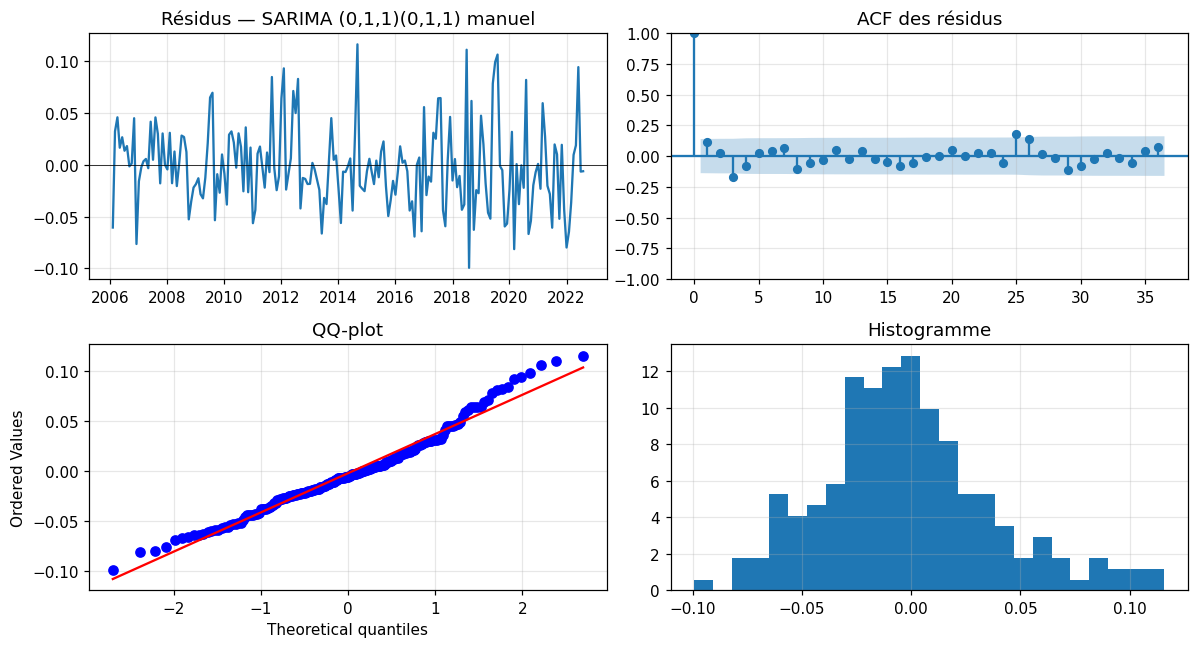

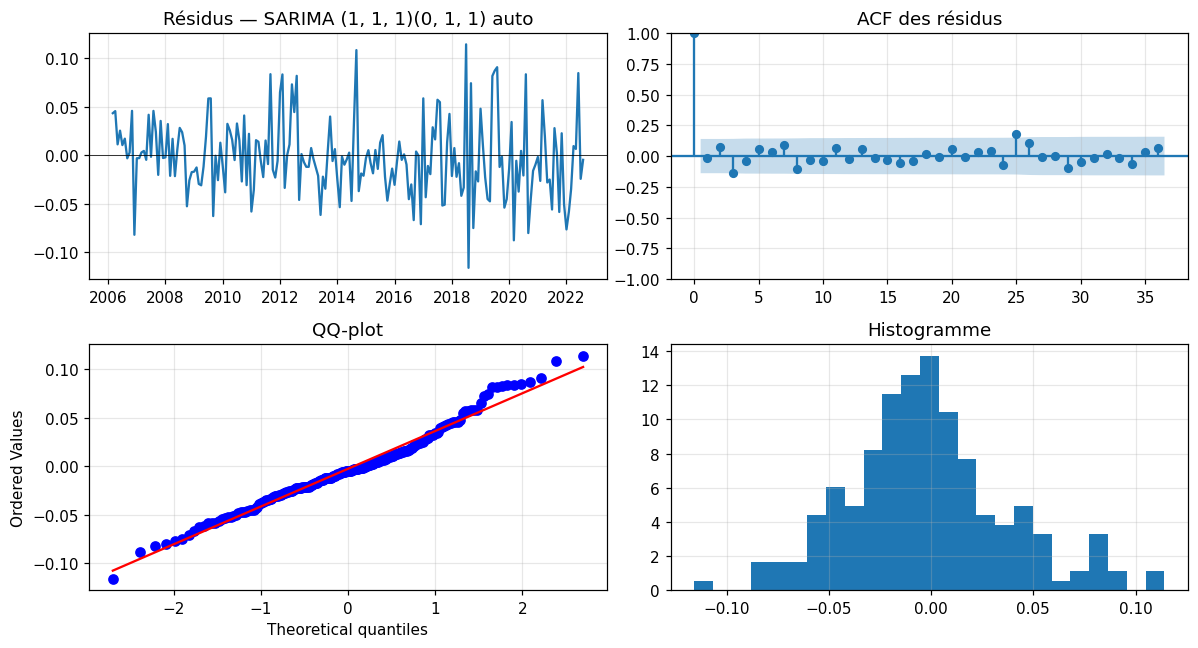

,LB(12) p,LB(24) p,JB p,Shapiro p,asymétrie,kurtosis exc.,ARCH-LM(12) p,σ résidu
modèle,,,,,,,,
"SARIMA (0,1,1)(0,1,1) manuel",0.127,0.605,0.003,0.002,0.538,0.457,0.006,0.039
"SARIMA (1, 1, 1)(0, 1, 1) auto",0.224,0.746,0.030,0.012,0.391,0.488,0.001,0.039


In [4]:
def clean_resid(m, order, seas):
    burn = order[1] + seas[1] * seas[3] + order[0] + seas[0] * seas[3]     # d + D*s + p + P*s
    return m.resid.iloc[burn:]

def diagnose(m, name, order, seas, plot=False):
    r = clean_resid(m, order, seas); npar = order[0] + order[2] + seas[0] + seas[2]
    lb = acorr_ljungbox(r, lags=[12, 24], model_df=npar, return_df=True)
    jb, sw, ar = stats.jarque_bera(r), stats.shapiro(r), het_arch(r, nlags=12)
    row = {"modèle": name, "LB(12) p": lb.lb_pvalue.iloc[0], "LB(24) p": lb.lb_pvalue.iloc[1],
           "JB p": jb[1], "Shapiro p": sw[1], "asymétrie": stats.skew(r), "kurtosis exc.": stats.kurtosis(r),
           "ARCH-LM(12) p": ar[1], "σ résidu": r.std()}
    if plot:
        fig, ax = plt.subplots(2, 2, figsize=(11, 6))
        ax[0, 0].plot(r); ax[0, 0].axhline(0, color="k", lw=.5); ax[0, 0].set_title(f"Résidus — {name}")
        plot_acf(r, lags=36, ax=ax[0, 1], title="ACF des résidus")
        stats.probplot(r, plot=ax[1, 0]); ax[1, 0].set_title("QQ-plot")
        ax[1, 1].hist(r, bins=25, density=True); ax[1, 1].set_title("Histogramme"); plt.tight_layout(); plt.show()
    return row

diag_rows = [diagnose(m_manual, "SARIMA (0,1,1)(0,1,1) manuel", (0, 1, 1), (0, 1, 1, 12), plot=True)]
auto_order, auto_seas = auto.order, auto.seasonal_order
m_auto = fit(auto_order, auto_seas, X0)
diag_rows.append(diagnose(m_auto, f"SARIMA {auto_order}{auto_seas[:3]} auto", auto_order, auto_seas, plot=True))
pd.DataFrame(diag_rows).set_index("modèle").round(3)

**Diagnostic des résidus (SARIMA sans température).**
- **Indépendance** : Ljung-Box ne rejette pas (p = 0,13 et 0,61 pour le manuel ; 0,22 et 0,75 pour l'auto) → plus d'autocorrélation linéaire exploitable : la dynamique linéaire est bien captée.
- **Normalité** : rejetée (Jarque-Bera p = 0,003 et Shapiro p = 0,002 pour le manuel), avec une légère asymétrie à droite (0,54) et un kurtosis modéré : les intervalles de prévision gaussiens ne sont qu'approximatifs.
- **ARCH-LM(12) : p = 0,006 (manuel) et 0,001 (auto) → effets ARCH présents** : la variance des résidus n'est pas constante. C'est le signal qui justifie la section 3.3 (GARCH).

## 4. Ajout de la température : SARIMAX
La température entre comme variable exogène. On compare trois candidats (même ordre (0,1,1)(0,1,1) pour isoler l'effet de l'exogène) sur le **même échantillon**, donc les AICc sont comparables.

In [5]:
cands = {"COVID seul": ["covid_2020_04"],
         "+ days_above_35": ["covid_2020_04", "days_above_35"],
         "+ cdd24": ["covid_2020_04", "cdd24"],
         "+ les deux": ["covid_2020_04", "days_above_35", "cdd24"]}
rows = []
for k, cols in cands.items():
    m = fit((0, 1, 1), (0, 1, 1, 12), train[cols])
    rows.append({"exogènes": k, "AICc": aicc(m), "BIC": m.bic, **{f"coef {c}": m.params[c] for c in cols[1:]},
                 **{f"p {c}": m.pvalues[c] for c in cols[1:]}})
display(pd.DataFrame(rows).set_index("exogènes").round(4))
print("corr(days_above_35, cdd24) sur le train =", round(train["days_above_35"].corr(train["cdd24"]), 2))

,AICc,BIC,coef days_above_35,p days_above_35,coef cdd24,p cdd24
exogènes,,,,,,
COVID seul,-657.9879,-645.3127,NaN,NaN,NaN,NaN
+ days_above_35,-704.1432,-688.3523,0.0075,0.0000,NaN,NaN
+ cdd24,-743.3933,-727.6024,NaN,NaN,0.0016,0.0
+ les deux,-739.9558,-721.0712,-0.0002,0.8894,0.0017,0.0


corr(days_above_35, cdd24) sur le train = 0.9


**Apport de la température.** L'ajout d'une variable de chaleur améliore l'ajustement de façon spectaculaire : AICc de −658 (COVID seul) à −704 avec `days_above_35` et à **−743 avec `cdd24`** (un gain de 85 points, bien au-delà de tout seuil usuel). Les deux variables sont très corrélées (0,90) ; mises ensemble, `days_above_35` devient non significatif (p = 0,89) et l'AICc se dégrade légèrement (−740) → on retient **`cdd24` seul**, qui mesure l'intensité de la chaleur et pas seulement le nombre de jours chauds.
Interprétation du coefficient (≈ 0,0017) : 100 degrés-jours de climatisation supplémentaires dans un mois sont associés à environ **+18 %** de production (exp(0,17) ≈ 1,19), toutes choses égales par ailleurs. C'est une association statistique conditionnelle au modèle, pas la preuve d'un effet causal.

In [6]:
EX = ["covid_2020_04", "cdd24"]                       # choix retenu (voir interprétation)
gx = grid(train[EX])
print("Grille SARIMAX (COVID + cdd24) — 5 meilleurs par AICc :"); display(gx.head(5).round(1)); print("retenu par la règle de parcimonie :", gx[gx.retenu][["p","q","P","Q"]].iloc[0].tolist())

Grille SARIMAX (COVID + cdd24) — 5 meilleurs par AICc :


,p,q,P,Q,AICc,BIC,retenu
0,1,1,0,1,-749.7,-730.8,True
1,2,1,0,1,-747.6,-725.6,False
2,0,2,0,1,-743.5,-724.7,False
3,0,1,0,1,-743.4,-727.6,False
4,1,1,1,1,-741.9,-719.9,False


retenu par la règle de parcimonie : [1, 1, 0, 1]


Avec `cdd24`, l'ordre (1,1,1)(0,1,1)₁₂ passe devant l'ordre airline (AICc −749,7 contre −743,4, écart de 6 ; le BIC préfère aussi l'AR(1) : −730,8 contre −727,6). L'AR(1) est donc justifié ici, contrairement au cas sans température.

SARIMAX retenu : (1, 1, 1)(0, 1, 1, 12)
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
covid_2020_04    -0.1864      0.058     -3.203      0.001      -0.301      -0.072
cdd24             0.0017      0.000     11.763      0.000       0.001       0.002
ar.L1             0.2536      0.093      2.738      0.006       0.072       0.435
ma.L1            -0.8302      0.059    -14.133      0.000      -0.945      -0.715
ma.S.L12         -0.8030      0.050    -16.156      0.000      -0.900      -0.706
sigma2            0.0009   9.41e-05      9.757      0.000       0.001       0.001


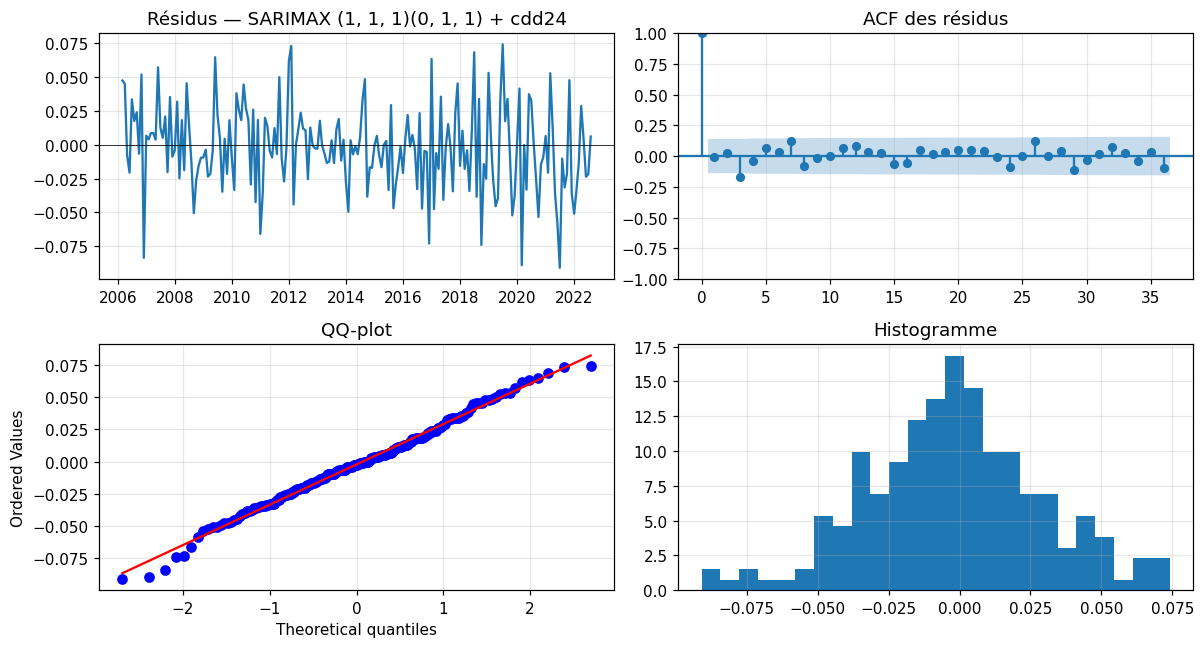

,LB(12) p,LB(24) p,JB p,Shapiro p,asymétrie,kurtosis exc.,ARCH-LM(12) p,σ résidu
modèle,,,,,,,,
"SARIMA (0,1,1)(0,1,1) manuel",0.127,0.605,0.003,0.002,0.538,0.457,0.006,0.039
"SARIMA (1, 1, 1)(0, 1, 1) auto",0.224,0.746,0.030,0.012,0.391,0.488,0.001,0.039
"SARIMAX (1, 1, 1)(0, 1, 1) + cdd24",0.119,0.521,0.800,0.477,-0.056,0.204,0.820,0.031


In [7]:
bx = gx[gx.retenu].iloc[0]; ox, sx = (int(bx.p), 1, int(bx.q)), (int(bx.P), 1, int(bx.Q), 12)
m_x = fit(ox, sx, train[EX])
print(f"SARIMAX retenu : {ox}{sx}"); print(m_x.summary().tables[1])
diag_rows2 = [diagnose(m_x, f"SARIMAX {ox}{sx[:3]} + cdd24", ox, sx, plot=True)]
# comparaison : même ordre, sans cdd24 (modèle auto sans température = référence de diagnostic)
pd.DataFrame(diag_rows + diag_rows2).set_index("modèle").round(3)

**Diagnostic du SARIMAX retenu.**
- Ljung-Box : p = 0,12 et 0,52 → pas d'autocorrélation résiduelle.
- **Normalité retrouvée** : Jarque-Bera p = 0,80, Shapiro p = 0,48, asymétrie ≈ 0.
- **Plus d'effet ARCH** : ARCH-LM(12) p = 0,82 (contre 0,006 sans température).
- L'écart-type des résidus baisse de 0,039 à 0,031 (−21 %).
- ⇒ Une partie de l'hétéroscédasticité et de la non-normalité du SARIMA venait des **chocs météo** non modélisés. *Conséquence pour la section 3.3* : sur le meilleur modèle (SARIMAX), un GARCH n'est pas justifié ; on l'estimera sur les résidus du SARIMA sans température, où les effets ARCH sont détectés, et on le rapportera honnêtement.

## 5. Prévisions et évaluation sur l'échantillon test
**Protocole** : origine fixe fin août 2022, prévisions h = 1…24 (test complet, sept. 2022 – août 2024). Métriques sur h = 10 (cadre de l'énoncé : 5 à 10 pas) et sur h = 24. Intervalles à 95 % calculés en log puis re-transformés.

**Deux versions SARIMAX** : *oracle* (température réelle du test, c'est une prévision **conditionnelle** — non opérationnelle) et *climatologie* (moyenne mensuelle de l'apprentissage, c'est la version réalisable sans prévision météo). Référence : **naïf saisonnier** (même mois un an avant).

In [8]:
H = len(test)
def forecast(m, exog_future):
    f = m.get_forecast(H, exog=exog_future); ci = np.exp(f.conf_int(alpha=.05))
    return pd.DataFrame({"fc": np.exp(f.predicted_mean), "lo": ci.iloc[:, 0], "hi": ci.iloc[:, 1]}, index=test.index)

Xt0 = test[["covid_2020_04"]]
clim = train.groupby(train.index.month)["cdd24"].mean()
Xclim = pd.DataFrame({"covid_2020_04": 0, "cdd24": clim.loc[test.index.month].values}, index=test.index)   # climatologie (sans prévision météo)

F = {"Naïf saisonnier": pd.DataFrame({"fc": pd.Series(np.tile(train["core"].values[-12:], 2), index=test.index)}),
     "SARIMA manuel": forecast(m_manual, Xt0),
     "SARIMA auto": forecast(m_auto, Xt0),
     "SARIMAX oracle": forecast(m_x, test[EX]),
     "SARIMAX climatologie": forecast(m_x, Xclim)}

rows = []
for name, f in F.items():
    r = {"modèle": name}
    for h in (10, 24):
        for k, v in metrics(test["core"], f["fc"], h).items(): r[f"{k} h={h}"] = v
    if "lo" in f: r["couverture IC95 %"] = 100 * ((test["core"] >= f["lo"]) & (test["core"] <= f["hi"])).mean()
    rows.append(r)
res = pd.DataFrame(rows).set_index("modèle")
display(res[[c for c in res.columns if "h=10" in c] + [c for c in res.columns if "h=24" in c] + ["couverture IC95 %"]].round(1))

,MSE h=10,RMSE h=10,MAE h=10,MAPE h=10,MSE h=24,RMSE h=24,MAE h=24,MAPE h=24,couverture IC95 %
modèle,,,,,,,,,
Naïf saisonnier,25214.3,158.8,119.3,8.6,21551.6,146.8,118.0,7.8,NaN
SARIMA manuel,24234.0,155.7,139.3,10.0,23141.7,152.1,133.0,9.1,54.2
SARIMA auto,25739.0,160.4,144.5,10.4,24457.8,156.4,136.4,9.4,54.2
SARIMAX oracle,13763.9,117.3,101.3,7.4,12829.6,113.3,100.0,7.0,66.7
SARIMAX climatologie,15754.2,125.5,111.5,7.9,23503.0,153.3,131.4,8.3,58.3


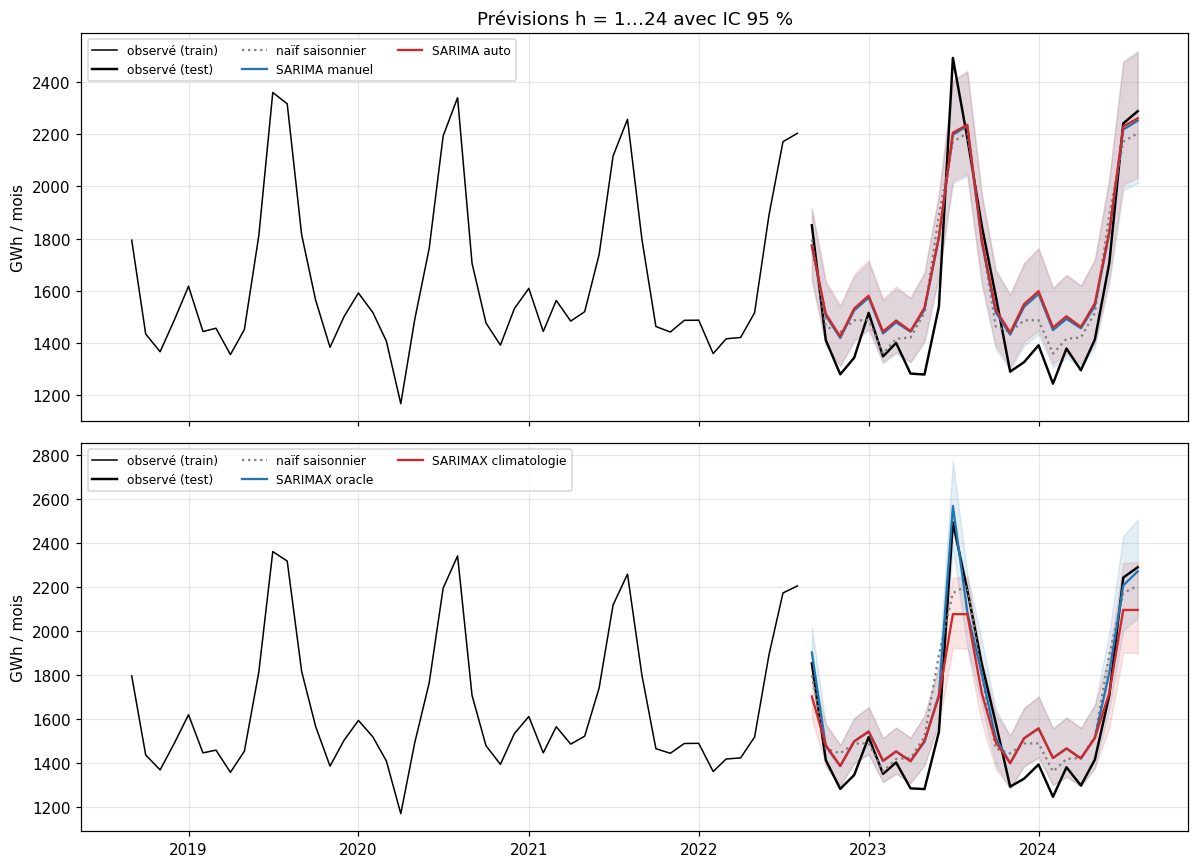

,Naïf saisonnier,SARIMA manuel,SARIMA auto,SARIMAX oracle,SARIMAX climatologie
month,,,,,
2022-09-01,2.9,4.3,4.1,-2.7,8.1
2022-12-01,-10.7,-13.5,-14.1,-11.4,-11.4
2023-03-01,-1.1,-5.6,-6.1,-3.6,-3.6
2023-06-01,-22.8,-17.2,-17.4,-11.0,-10.5
2023-07-01,12.9,11.8,11.5,-3.0,16.7
2023-08-01,-0.9,-2.2,-2.4,4.6,5.0
2023-11-01,-11.8,-11.0,-11.6,-8.3,-8.3
2023-12-01,-12.1,-16.0,-16.8,-13.8,-13.8
2024-03-01,-2.7,-8.2,-9.0,-6.2,-6.2


In [9]:
fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for a, names in zip(ax, [["SARIMA manuel", "SARIMA auto"], ["SARIMAX oracle", "SARIMAX climatologie"]]):
    a.plot(train.index[-48:], train["core"].iloc[-48:], color="k", lw=1, label="observé (train)")
    a.plot(test.index, test["core"], color="k", lw=1.6, label="observé (test)")
    a.plot(test.index, F["Naïf saisonnier"]["fc"], color="gray", ls=":", label="naïf saisonnier")
    for n, c in zip(names, ["tab:blue", "tab:red"]):
        a.plot(test.index, F[n]["fc"], color=c, label=n); a.fill_between(test.index, F[n]["lo"], F[n]["hi"], color=c, alpha=.12)
    a.set_ylabel("GWh / mois"); a.legend(ncol=3, fontsize=8)
ax[0].set_title("Prévisions h = 1…24 avec IC 95 %"); plt.tight_layout(); plt.show()

# erreurs relatives par mois : où les modèles se trompent-ils ?
err = pd.DataFrame({n: 100 * (test["core"] - f["fc"]) / test["core"] for n, f in F.items()})
display(err.round(1).iloc[[0, 3, 6, 9, 10, 11, 14, 15, 18, 22, 23]])

**Lecture des prévisions (origine fixe août 2022, 24 mois de test).**
- **Les SARIMA purs ne battent pas la référence naïve saisonnière** sur ce test : RMSE sur 24 mois de 152 (manuel) et 156 (auto) contre 147 (naïf) ; MAPE 9,1 % et 9,4 % contre 7,8 %. Sur h = 10, le manuel est à peine meilleur (156 contre 159) mais plus mauvais en MAE (139 contre 119).
- **D'où vient l'erreur** : les modèles *surestiment* les mois hors été (par exemple décembre 2022 : prévision supérieure de 13,5 % à l'observé ; décembre 2023 : 16 % ; juin 2023 : 17 %). Estimés sur une histoire de croissance (+3 à +5 % par an avant 2020), ils prolongent cette croissance alors que la production annuelle a stagné ou reculé après 2019 (2020 : −2,5 % ; 2021 : +1,8 % ; 2022 : −2,9 % ; 2023 : −1,3 %). C'est une **rupture de tendance non modélisée** (non testée formellement ici ; ses causes — importations, économie, efficacité — ne sont pas établies par nos données).
- **SARIMAX « oracle »** (température réelle du test) : RMSE 113 sur 24 mois (−23 % par rapport au naïf) et 117 sur h = 10 (−26 %) ; il capte le pic de juillet 2023 (erreur −3 % contre +12 % pour le SARIMA). **Attention** : c'est une prévision *conditionnelle* à une météo connue à l'avance, non opérationnelle ; elle mesure la valeur de l'information météo, pas la performance réelle d'un système de prévision.
- **SARIMAX « climatologie »** (version réalisable) : très bon sur h = 10 (RMSE 125,5, −21 % par rapport au naïf) mais **sans gain sur 24 mois** (153 contre 147) : sans prévision météo, les pics extrêmes des étés 2023 et 2024 ne sont pas anticipés (juillet 2023 : erreur de +17 %). La raison précise du bon score à h = 10 n'est pas isolée ici ; la fenêtre h = 10 (sept. 2022 – juin 2023) ne contient aucun été.
- **Intervalles de prévision trop étroits** : la couverture réelle des IC à 95 % n'est que de 54 % pour les SARIMA (58 % pour le SARIMAX climatologie, 67 % pour l'oracle). Les intervalles ne reflètent que le bruit estimé sur l'apprentissage, pas la rupture de tendance ni l'incertitude météo : ils sous-estiment le risque réel.
- **Prudence statistique** : avec 24 points de test, ces écarts ne sont pas encore testés ; le test de Diebold-Mariano (section 6) dira lesquels sont significatifs.

In [10]:
# Sauvegarde des prévisions (échelle GWh) pour le tableau récapitulatif et Diebold-Mariano (section 6)
for n, f in F.items(): save_forecasts(n, f["fc"])
res.round(3).to_csv("results/metrics_sarima.csv"); print("sauvé : results/forecasts.csv, results/metrics_sarima.csv")

sauvé : results/forecasts.csv, results/metrics_sarima.csv


## Synthèse et suite
| Point | Conclusion |
|---|---|
| Modèle de référence classique | SARIMA(0,1,1)(0,1,1)₁₂ + COVID — parcimonieux, équivalent à l'auto (1,1,1)(0,1,1)₁₂ selon AICc/BIC |
| Meilleur modèle | SARIMAX(1,1,1)(0,1,1)₁₂ + COVID + `cdd24` : résidus propres (indépendants, normaux, sans ARCH), AICc −749,7 |
| Valeur de la température | très forte en ajustement ; en prévision, elle exige une **météo future connue ou prévue** |
| Prévision | les modèles purs ne battent pas le naïf saisonnier sur 2022–2024 : rupture de tendance non modélisée |
| Incertitude | IC à 95 % réellement couverts à 54–67 % seulement |
| Pour 3.3 (GARCH) | effets ARCH présents dans le SARIMA, absents dans le SARIMAX → GARCH sur les résidus du SARIMA, résultat à rapporter honnêtement |
| Pour la suite | VAR/VECM (`log core` et température), LSTM/GRU avec validation walk-forward, évaluation par Diebold-Mariano ; envisager une réestimation glissante pour limiter l'effet de la rupture |

Les prévisions des cinq modèles sont sauvegardées dans `results/forecasts.csv` pour le tableau comparatif unique et le test de Diebold-Mariano.